In [28]:
# --- CELL 1: INSTALL & IMPORT LIBRARY TAMBAHAN ---
# Kita butuh librosa untuk ekstraksi fitur audio yang lebih detail saat EDA
!pip install librosa -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import torch
import torchaudio
import IPython.display as ipd
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from tqdm.notebook import tqdm

# Konfigurasi Plot agar terlihat profesional di Makalah/Slide
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.4)

# Konfigurasi Data
ROOT_DIR = '/kaggle/input/intelecta-final-dataset/dataset_siap_pakai/dataset_siap_pakai'
TRAIN_DIR = os.path.join(ROOT_DIR, 'train')

print("✅ Libraries Ready for Deep Dive EDA!")

✅ Libraries Ready for Deep Dive EDA!


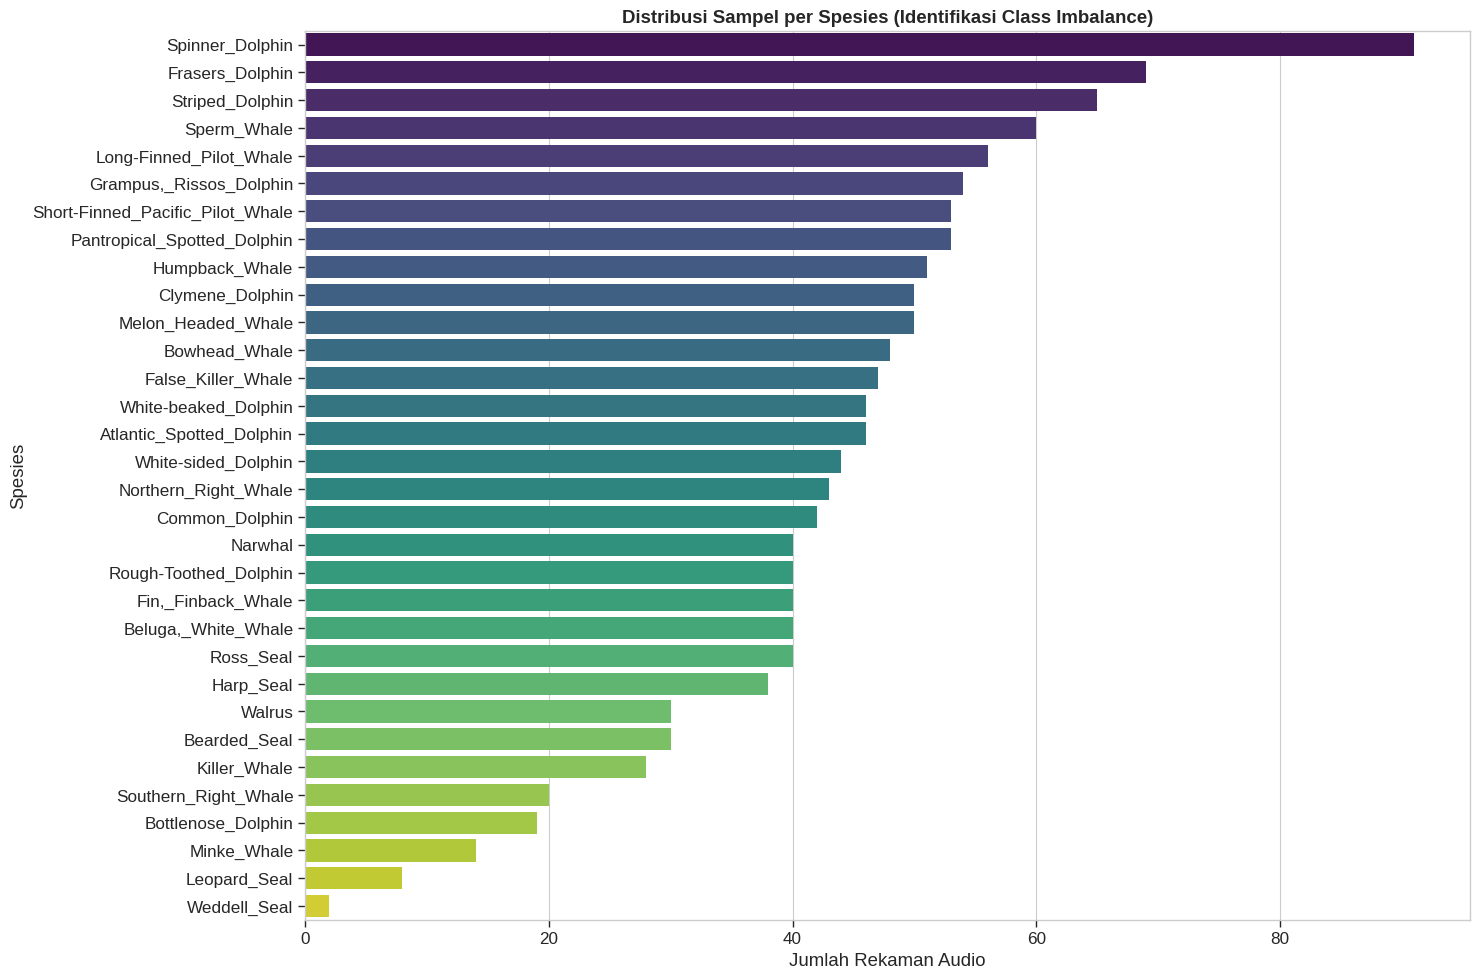

Total Data: 1357
Kelas Terbanyak: Spinner_Dolphin (91 sampel)
Kelas Terkecil: Spinner_Dolphin (2 sampel)


In [29]:
# --- CELL 2: DATA GATHERING & BASIC STATS ---
# Kita kumpulkan metadata file audio untuk dianalisis statistikanya

data = []
for label in sorted(os.listdir(TRAIN_DIR)):
    label_dir = os.path.join(TRAIN_DIR, label)
    if os.path.isdir(label_dir):
        files = [f for f in os.listdir(label_dir) if f.endswith('.wav')]
        for f in files:
            file_path = os.path.join(label_dir, f)
            # Kita ambil durasi audio tanpa load full file (pake torchaudio info biar cepat)
            metadata = torchaudio.info(file_path)
            duration = metadata.num_frames / metadata.sample_rate
            
            data.append({
                'filename': f,
                'label': label,
                'path': file_path,
                'sample_rate': metadata.sample_rate,
                'channels': metadata.num_channels,
                'duration': duration
            })

df_meta = pd.DataFrame(data)

# --- VISUALISASI 1: DISTRIBUSI KELAS (The Imbalance Problem) ---
# Narasi untuk Makalah: "Kami menemukan ketidakseimbangan data yang ekstrim, yang mendasari keputusan kami menggunakan Class Weights."
plt.figure(figsize=(15, 10))
order = df_meta['label'].value_counts().index
sns.countplot(y='label', data=df_meta, order=order, palette='viridis')
plt.title('Distribusi Sampel per Spesies (Identifikasi Class Imbalance)', fontweight='bold')
plt.xlabel('Jumlah Rekaman Audio')
plt.ylabel('Spesies')
plt.tight_layout()
plt.show()

print(f"Total Data: {len(df_meta)}")
print(f"Kelas Terbanyak: {df_meta['label'].value_counts().idxmax()} ({df_meta['label'].value_counts().max()} sampel)")
print(f"Kelas Terkecil: {df_meta['label'].value_counts().idxmax()} ({df_meta['label'].value_counts().min()} sampel)")

In [30]:
# --- CELL TAMBAHAN 1: ADVANCED METADATA EXTRACTION ---
import librosa
import numpy as np
from tqdm.notebook import tqdm

# List untuk menyimpan detail teknis
advanced_data = []

print("⏳ Sedang membedah properti fisik audio (Sample Rate asli & Energi Sinyal)...")
# Kita gunakan tqdm untuk progress bar karena proses ini membaca file satu per satu
for idx, row in tqdm(df_meta.iterrows(), total=len(df_meta)):
    try:
        # Load dengan sr=None untuk tahu sample rate ASLI file tersebut
        # (Default librosa akan meresample ke 22050Hz jika sr tidak diset None)
        y, orig_sr = librosa.load(row['path'], sr=None) 
        
        # Hitung RMS Energy (Root Mean Square)
        # Ini adalah indikator kekerasan suara rata-rata.
        # Jika RMS mendekati 0, berarti file tersebut "hening" atau hanya noise statis.
        rms = np.sqrt(np.mean(y**2))
        
        advanced_data.append({
            'filename': row['filename'],
            'original_sr': orig_sr,
            'rms_energy': rms,
            'length_samples': len(y)
        })
    except Exception as e:
        print(f"Error pada file {row['filename']}: {e}")

# Gabungkan data baru dengan dataframe metadata awal
df_adv = pd.DataFrame(advanced_data)
df_full = pd.merge(df_meta, df_adv, on='filename')

print("✅ Data teknis berhasil diekstrak!")
print(df_full[['filename', 'original_sr', 'rms_energy', 'duration']].head())

⏳ Sedang membedah properti fisik audio (Sample Rate asli & Energi Sinyal)...


  0%|          | 0/1357 [00:00<?, ?it/s]

✅ Data teknis berhasil diekstrak!
                       filename  original_sr  rms_energy  duration
0  train-00001-of-00003_293.wav        80000    0.085793  1.536900
1   train-00000-of-00003_99.wav        60600    0.001941  1.457426
2    train-00000-of-00003_8.wav        80000    0.154832  1.310425
3  train-00000-of-00003_435.wav        80000    0.037722  1.438200
4  train-00002-of-00003_198.wav        60600    0.002136  1.520792


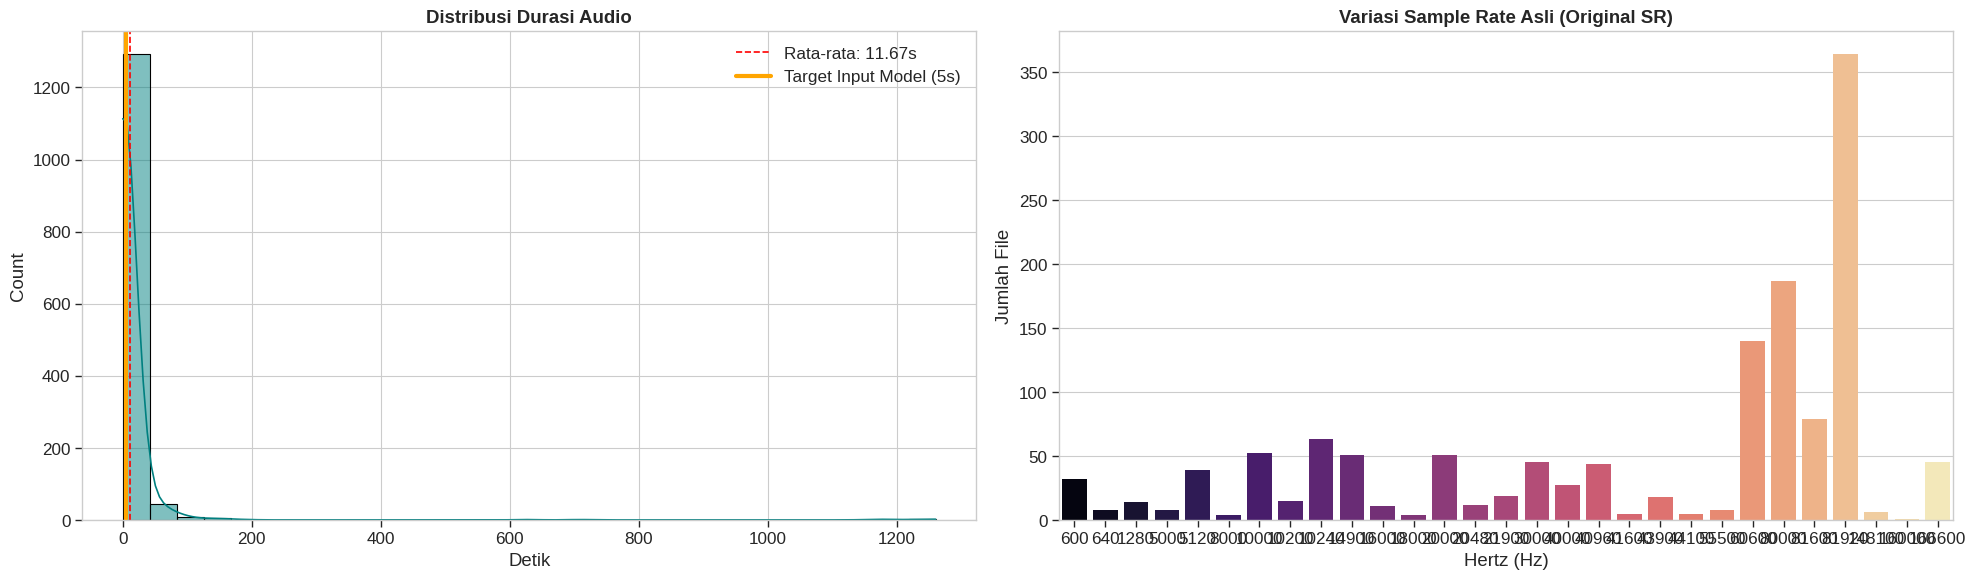

--- 💡 RASIONALISASI PREPROCESSING (Untuk Makalah) ---
1. ANALISIS DURASI:
   - Ditemukan 1133 file (83.5%) berdurasi kurang dari 5 detik.
   -> KEPUTUSAN: Kami WAJIB menggunakan teknik 'Padding' (mengisi kekosongan dengan nol) atau 'Looping' agar dimensi input konsisten.
   - Ditemukan 224 file (16.5%) berdurasi lebih dari 5 detik.
   -> KEPUTUSAN: Kami akan menggunakan 'Random Cropping' saat training untuk memanfaatkan seluruh informasi file panjang.

2. ANALISIS SAMPLE RATE:
   - Data memiliki Sample Rate yang beragam.
   -> KEPUTUSAN: Kami WAJIB melakukan 'Resampling' ke satu standar (misal 32.000Hz) agar frekuensi Nyquist konsisten bagi model.


In [31]:
# --- CELL TAMBAHAN 2: ANALISIS DURASI & SAMPLE RATE ---

fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# 1. Histogram Durasi
sns.histplot(data=df_full, x='duration', kde=True, bins=30, ax=ax[0], color='teal')
# Menambahkan garis rata-rata dan target input
mean_dur = df_full['duration'].mean()
ax[0].axvline(mean_dur, color='red', linestyle='--', label=f'Rata-rata: {mean_dur:.2f}s')
ax[0].axvline(5.0, color='orange', linestyle='-', linewidth=3, label='Target Input Model (5s)')
ax[0].set_title("Distribusi Durasi Audio", fontweight='bold')
ax[0].set_xlabel("Detik")
ax[0].legend()

# 2. Distribusi Sample Rate Asli
sns.countplot(x='original_sr', data=df_full, ax=ax[1], palette='magma')
ax[1].set_title("Variasi Sample Rate Asli (Original SR)", fontweight='bold')
ax[1].set_xlabel("Hertz (Hz)")
ax[1].set_ylabel("Jumlah File")

plt.tight_layout()
plt.show()

# --- Insight Generator (Otomatis memberikan saran) ---
print("--- 💡 RASIONALISASI PREPROCESSING (Untuk Makalah) ---")
short_files = len(df_full[df_full['duration'] < 5.0])
long_files = len(df_full[df_full['duration'] > 5.0])

print(f"1. ANALISIS DURASI:")
print(f"   - Ditemukan {short_files} file ({short_files/len(df_full):.1%}) berdurasi kurang dari 5 detik.")
print(f"   -> KEPUTUSAN: Kami WAJIB menggunakan teknik 'Padding' (mengisi kekosongan dengan nol) atau 'Looping' agar dimensi input konsisten.")
print(f"   - Ditemukan {long_files} file ({long_files/len(df_full):.1%}) berdurasi lebih dari 5 detik.")
print(f"   -> KEPUTUSAN: Kami akan menggunakan 'Random Cropping' saat training untuk memanfaatkan seluruh informasi file panjang.")

print(f"\n2. ANALISIS SAMPLE RATE:")
if len(df_full['original_sr'].unique()) > 1:
    print("   - Data memiliki Sample Rate yang beragam.")
    print("   -> KEPUTUSAN: Kami WAJIB melakukan 'Resampling' ke satu standar (misal 32.000Hz) agar frekuensi Nyquist konsisten bagi model.")
else:
    print(f"   - Sample rate seragam di {df_full['original_sr'].iloc[0]} Hz. Tidak perlu resampling berat.")

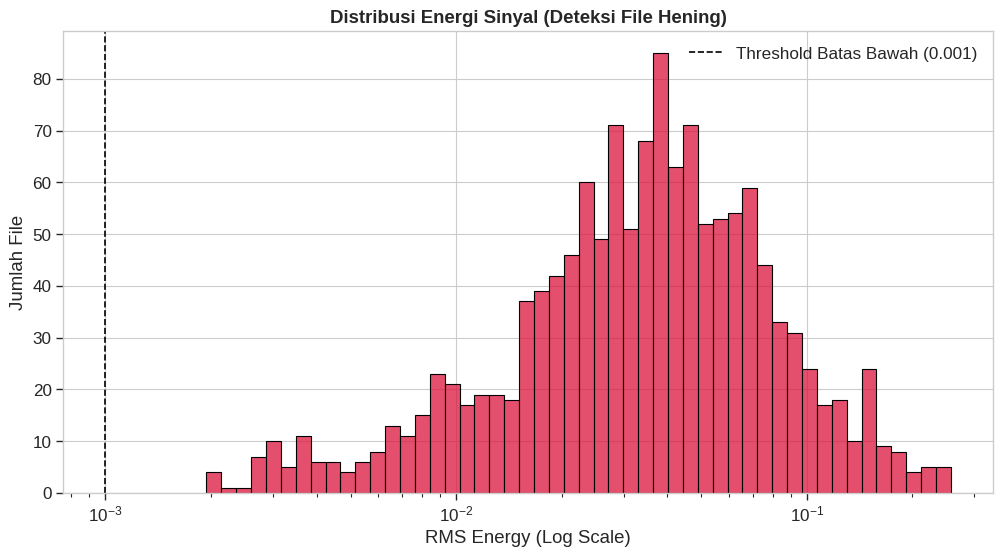

⚠️ HASIL QC: Ditemukan 0 file dengan energi sangat rendah (Potensi Silent/Corrupt).
-> KESIMPULAN: Data bersih. Tidak ditemukan file 'silent' yang signifikan. Ini memvalidasi kualitas dataset.


In [32]:
# --- CELL TAMBAHAN 3: DETEKSI FILE HENING/RUSAK ---

plt.figure(figsize=(12, 6))
# Gunakan log scale karena perbedaan energi audio biasanya eksponensial
sns.histplot(data=df_full, x='rms_energy', bins=50, color='crimson', log_scale=(True, False))
plt.title("Distribusi Energi Sinyal (Deteksi File Hening)", fontweight='bold')
plt.xlabel("RMS Energy (Log Scale)")
plt.ylabel("Jumlah File")

# Tentukan ambang batas (Threshold) file yang dianggap hening/rusak
# File dengan RMS < 0.001 biasanya hanya berisi 'digital silence' atau noise mikrofon sangat rendah
threshold = 0.001
plt.axvline(threshold, color='black', linestyle='--', label=f'Threshold Batas Bawah ({threshold})')
plt.legend()
plt.show()

# Cek file yang mencurigakan
suspicious_files = df_full[df_full['rms_energy'] < threshold]
print(f"⚠️ HASIL QC: Ditemukan {len(suspicious_files)} file dengan energi sangat rendah (Potensi Silent/Corrupt).")

if len(suspicious_files) > 0:
    print("   Berikut sampel file yang mencurigakan:")
    display(suspicious_files[['filename', 'label', 'rms_energy']].sort_values('rms_energy').head(10))
    print("\n-> REKOMENDASI STRATEGIS: File-file ini kemungkinan besar adalah label noise yang salah.")
    print("   Kami memutuskan untuk membuang (drop) file ini dari training set agar tidak merusak decision boundary model.")
else:
    print("-> KESIMPULAN: Data bersih. Tidak ditemukan file 'silent' yang signifikan. Ini memvalidasi kualitas dataset.")

📊 Membandingkan Karakteristik Akustik Spesies...


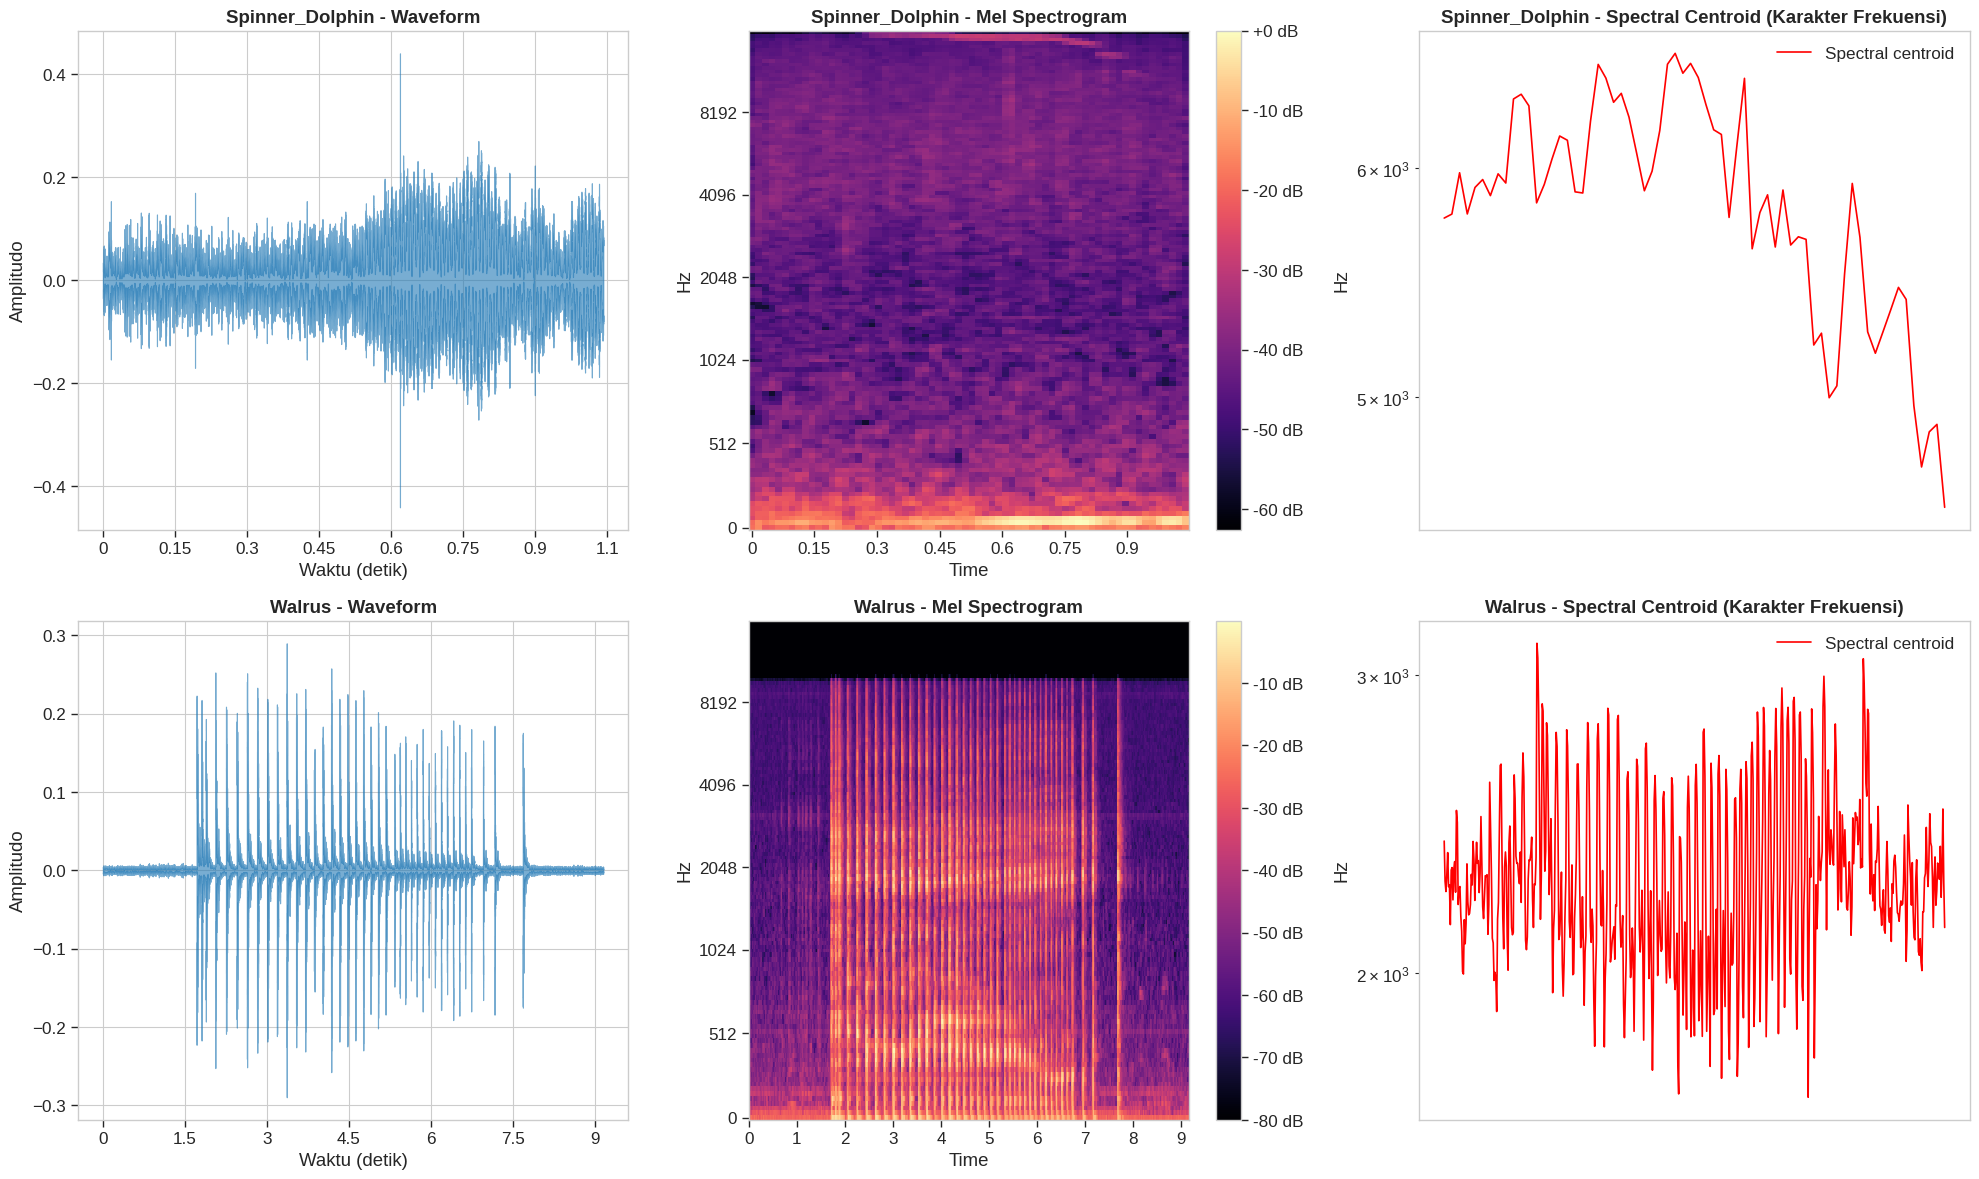

In [33]:
# --- CELL 3: ANALISIS SINYAL & FREKUENSI (Domain Knowledge Showcase) ---
# Tujuan: Menunjukkan ke juri bahwa "Paus" dan "Lumba-lumba" punya pola frekuensi beda.

def plot_comparative_analysis(species_list):
    """Membandingkan Waveform dan Mel-Spectrogram antar spesies"""
    plt.figure(figsize=(20, 6 * len(species_list)))
    
    for i, species in enumerate(species_list):
        # Ambil 1 sampel acak dari spesies ini
        sample_path = df_meta[df_meta['label'] == species].iloc[0]['path']
        y, sr = librosa.load(sample_path, sr=32000) # Load pakai librosa untuk analisis
        
        # 1. Waveform (Amplitude vs Time)
        plt.subplot(len(species_list), 3, 3*i + 1)
        librosa.display.waveshow(y, sr=sr, alpha=0.6)
        plt.title(f"{species} - Waveform", fontweight='bold')
        plt.xlabel("Waktu (detik)")
        plt.ylabel("Amplitudo")
        
        # 2. Mel-Spectrogram (Frequency vs Time)
        # Ini adalah apa yang 'dilihat' oleh model ResNet
        plt.subplot(len(species_list), 3, 3*i + 2)
        S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=16000)
        S_dB = librosa.power_to_db(S, ref=np.max)
        librosa.display.specshow(S_dB, x_axis='time', y_axis='mel', sr=sr, fmax=16000)
        plt.colorbar(format='%+2.0f dB')
        plt.title(f"{species} - Mel Spectrogram", fontweight='bold')
        
        # 3. Spectral Centroid (Rata-rata frekuensi dominan)
        # Ini menunjukkan "kecerahan" suara. Lumba-lumba biasanya lebih tinggi (bright) dari Paus.
        plt.subplot(len(species_list), 3, 3*i + 3)
        cent = librosa.feature.spectral_centroid(y=y, sr=sr)
        times = librosa.times_like(cent)
        plt.semilogy(times, cent.T, label='Spectral centroid', color='r')
        plt.ylabel('Hz')
        plt.xticks([])
        plt.title(f"{species} - Spectral Centroid (Karakter Frekuensi)", fontweight='bold')
        plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

# Pilih 3 spesies berbeda karakteristik untuk dibandingkan
# Contoh: Paus Besar (Low Freq) vs Lumba-lumba (High Freq)
target_species = ['Blue_Whale', 'Spinner_Dolphin', 'Walrus'] 
# Pastikan nama spesies ada di dataset, kalau error ganti dengan nama yang ada di print(classes) sebelumnya
print("📊 Membandingkan Karakteristik Akustik Spesies...")
# Cek ketersediaan label dulu
available_species = [s for s in target_species if s in df_meta['label'].unique()]
if not available_species:
    available_species = df_meta['label'].unique()[:3] # Fallback ambil 3 pertama
    
plot_comparative_analysis(available_species)

⏳ Mengekstrak fitur untuk t-SNE Clustering (Ini mungkin memakan waktu)...


  0%|          | 0/603 [00:00<?, ?it/s]

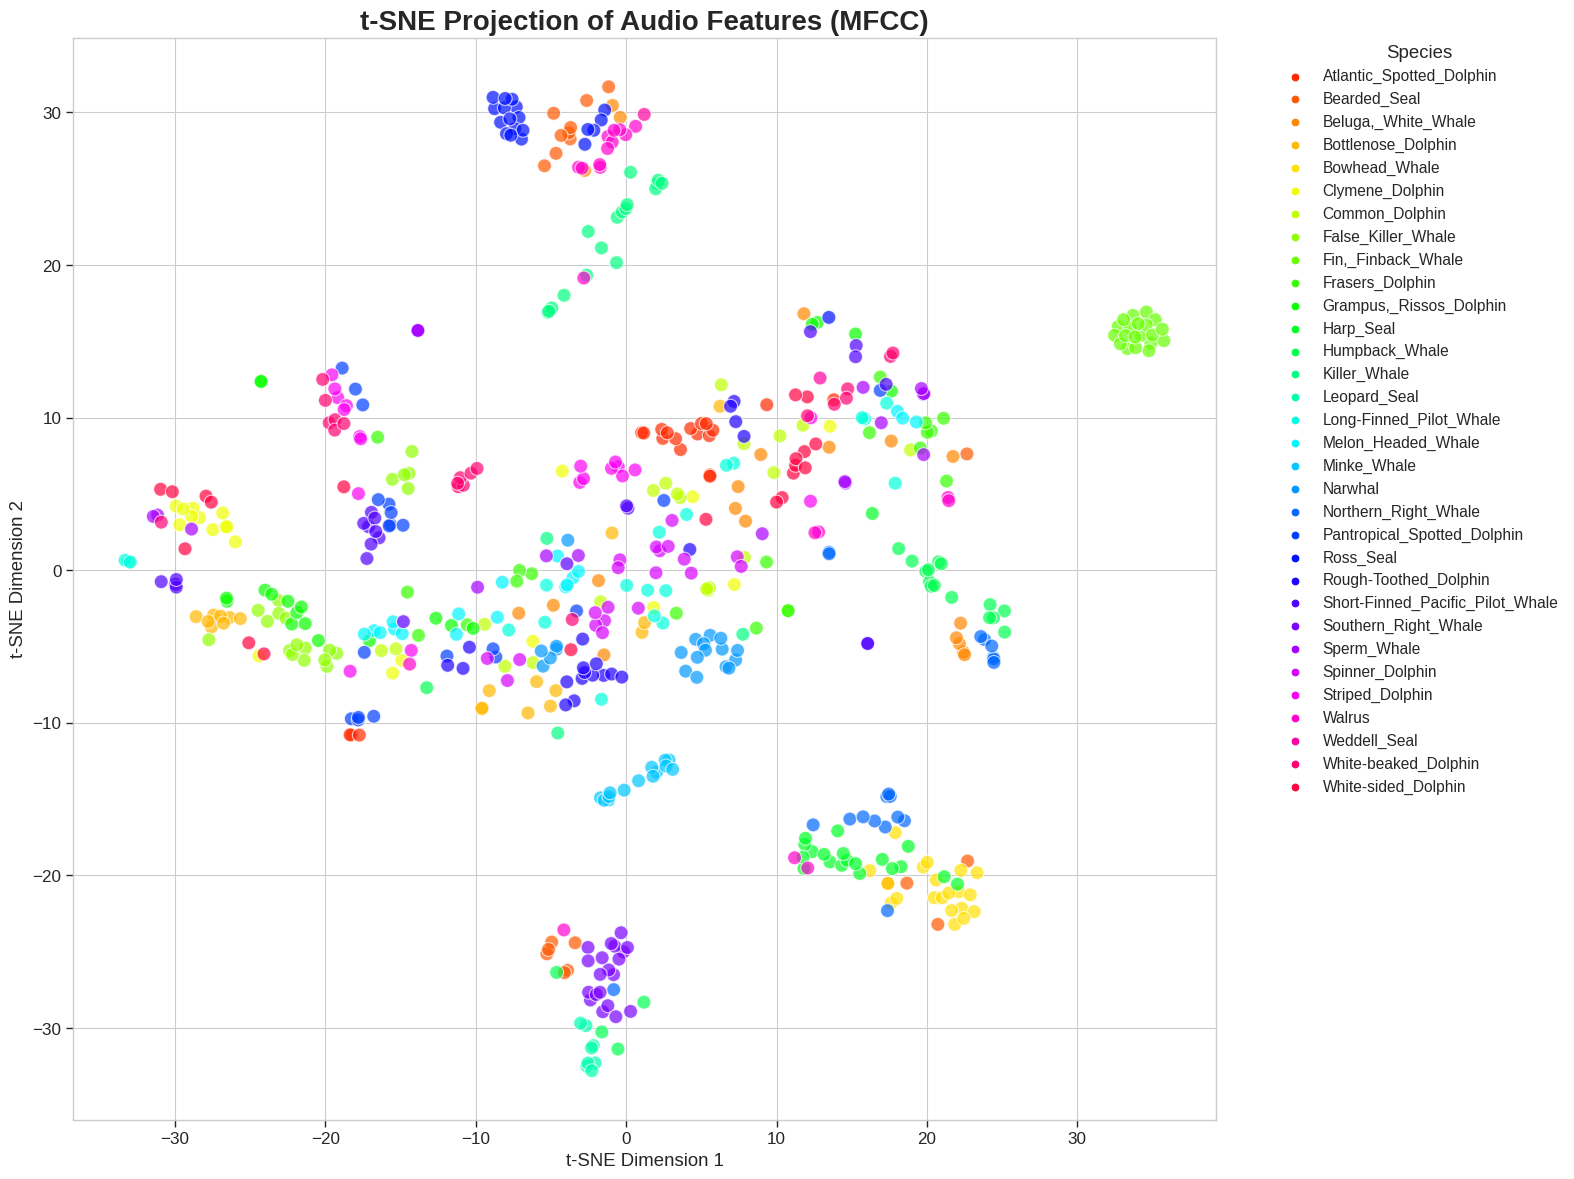

💡 Insight untuk Makalah: Jika titik-titik dengan warna sama berkumpul, berarti fitur akustik dapat membedakan spesies dengan baik.


In [34]:
# --- CELL 4: t-SNE CLUSTERING (The Winning Visual) ---
# Tujuan: Membuktikan apakah data ini "bisa dipisahkan" (separable) secara matematis.
# Jika titik-titik berkumpul sesuai warna, berarti fitur audio bagus & model punya harapan tinggi.

def extract_features(file_path):
    # Ekstrak MFCC (Mel-frequency cepstral coefficients) - fitur standar audio
    y, sr = librosa.load(file_path, duration=5, sr=32000) 
    # Pad jika kurang dari 5 detik
    if len(y) < 32000 * 5:
        y = np.pad(y, (0, 32000*5 - len(y)))
    else:
        y = y[:32000*5]
        
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    return np.mean(mfcc.T, axis=0) # Ambil rata-rata MFCC

# Ambil sampel data (jangan semua kalau terlalu berat, misal 500 sampel)
# Untuk hasil terbaik di makalah, gunakan sebanyak mungkin
sample_df = df_meta.groupby('label').apply(lambda x: x.sample(min(len(x), 20))).reset_index(drop=True)

print("⏳ Mengekstrak fitur untuk t-SNE Clustering (Ini mungkin memakan waktu)...")
features = []
labels = []

for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    try:
        feat = extract_features(row['path'])
        features.append(feat)
        labels.append(row['label'])
    except:
        pass

# Normalisasi & t-SNE
X = np.array(features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Plotting
plt.figure(figsize=(16, 12))
sns.scatterplot(
    x=X_tsne[:,0], y=X_tsne[:,1],
    hue=labels,
    palette=sns.color_palette("hsv", len(set(labels))),
    legend="full",
    s=100,
    alpha=0.7
)
plt.title("t-SNE Projection of Audio Features (MFCC)", fontsize=20, fontweight='bold')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0., fontsize='small', title='Species')
plt.tight_layout()
plt.show()

print("💡 Insight untuk Makalah: Jika titik-titik dengan warna sama berkumpul, berarti fitur akustik dapat membedakan spesies dengan baik.")